# Lab 04 — Performance measures and comparing classifiers

*Machine Learning and Data Mining — Claudio Sartori, University of Bologna*

## Goal of this lab

Lab 3 ended with a question: the NordicMart tree chosen by accuracy finds 22 of 108 churners — is accuracy the right number
to choose with? Lecture 10b gave the toolbox, Lecture 11 three new classifiers. Today we put both into code, and we end by
teaching `GridSearchCV` to choose with **NordicMart's own money**.

| # | Step | Where |
|---|---|---|
| 1 | Confusion matrix, precision, recall, F1, κ, MCC — the numbers of Lecture 10b | A |
| 2 | Probabilities and thresholds | A |
| 3 | Change `scoring`, change the winner | B |
| 4 | Four classifiers with pipelines: tree, Naïve Bayes, logistic regression, kNN | C |
| 5 | One look at the test set: AUC, log loss, ROC curves | C |
| 6 | **A custom scorer with the churn costs**: cost-sensitive selection, then the threshold | D |
| ★ | The threshold tuned by scikit-learn; a different cost matrix; multi-class averages | E |

- **Part A (≈ 25 min)** — the tree of Lecture 10b, read with all the measures.
- **Part B (≈ 15 min)** — the grid of Lab 3, with six different `scoring`.
- **Part C (≈ 30 min)** — the comparison table of Lecture 11, rebuilt.
- **Part D (≈ 35 min)** — the cost experiment.
- Exercises marked ★ are optional: do them if you have time, or at home.

### How to work (as in Labs 1–3)

- Write code in the empty cells; write **answers in markdown cells**, not in comments.
- Raw data are never modified: every change goes into a copy with a new name.
- Every random step gets a fixed `random_state`, so that your numbers are the same as the slides'.
- The **test set is the future**. In Part A we look at it only to *reproduce* the slides of Lecture 10b: no choice is made there.
  From Part B on, every choice is made with cross-validation on the training part; the test set is opened once in C5 and once in D5.
- Before closing: **Kernel → Restart & Run All**.

## Setup

New imports: the measures of Lecture 10b (`sklearn.metrics`), the three classifiers of Lecture 11, the pieces of a pipeline,
`DummyClassifier` (the "nobody churns" baseline as a real model), `make_scorer` to build our own scoring, and
`cross_val_predict` (out-of-fold predictions).

In [23]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict,
                                     TunedThresholdClassifierCV)
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_iris
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score, cohen_kappa_score, matthews_corrcoef, classification_report,
                             roc_auc_score, roc_curve, log_loss, make_scorer)
import sklearn

DATA_DIR = Path("../data")
NORDICMART_FILE = DATA_DIR / "nordicmart_customers.csv"
SEED = 42

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (8, 4)

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 3.1.0


`TunedThresholdClassifierCV` (used only in ★ E1) needs scikit-learn 1.5 or later. If the import fails, update scikit-learn
or remove it from the import list.

# Part A — Reading a classifier with all the measures

## A1. Data, split, folds

The same preparation as Lab 3, Part C: run the cell, do not change it.

In [24]:
df = pd.read_csv(NORDICMART_FILE)
FEATURES = ["tier", "age", "days_since_last_buy", "annual_spend", "web_sessions_month", "tickets_90d"]
Xn = df[FEATURES].copy()
Xn["tier"] = Xn["tier"].map({"Basic": 0, "Silver": 1, "Gold": 2})
yn = df["churned"]

Xn_train, Xn_test, yn_train, yn_test = train_test_split(Xn, yn, test_size=0.3, stratify=yn, random_state=SEED)
cv_n = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
print(f"training: {len(yn_train)} customers, {yn_train.sum()} churners | test: {len(yn_test)} customers, {yn_test.sum()} churners")

training: 2100 customers, 252 churners | test: 900 customers, 108 churners


## A2. The confusion matrix

The running tree of Lecture 10b is `DecisionTreeClassifier(max_depth=4, min_samples_leaf=30, random_state=0)`: the configuration
that 5-fold CV chooses when the score is AUC (we will check it in Part B).

1. Learn it on the training part; call it `tree_10b`. Predict the test set: `pred_10b`.
1. [`confusion_matrix(y_true, y_pred)`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html):
   print it. Which row is "true churn"? Which column is "predicted churn"?
1. `.ravel()` flattens it into `tn, fp, fn, tp` (in this order, for labels 0 and 1). Print the four numbers.
1. Draw it with `ConfusionMatrixDisplay.from_predictions(..., display_labels=["stay", "churn"])`.

Confusion Matrix:
[[764  28]
 [ 82  26]]

True Negatives (tn): 764
False Positives (fp): 28
False Negatives (fn): 82
True Positives (tp): 26


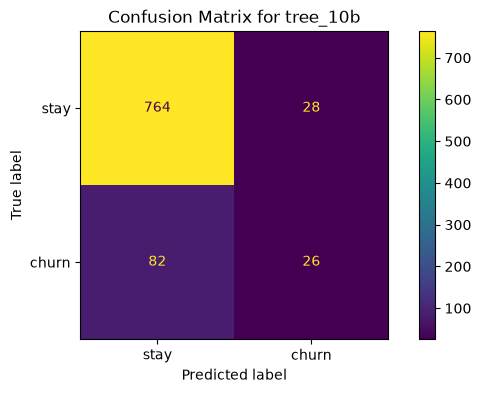

In [25]:
# 1. Learn the tree on the training part and predict the test set
tree_10b = DecisionTreeClassifier(max_depth=4, min_samples_leaf=30, random_state=0)
tree_10b.fit(Xn_train, yn_train)
pred_10b = tree_10b.predict(Xn_test)

# 2 & 3. Calculate and print the confusion matrix
cm = confusion_matrix(yn_test, pred_10b)
print("Confusion Matrix:")
print(cm)

# 4. Flatten the matrix into tn, fp, fn, tp and print them
tn, fp, fn, tp = cm.ravel()
print(f"\nTrue Negatives (tn): {tn}")
print(f"False Positives (fp): {fp}")
print(f"False Negatives (fn): {fn}")
print(f"True Positives (tp): {tp}")

# 5. Draw it with ConfusionMatrixDisplay
disp = ConfusionMatrixDisplay.from_predictions(
    yn_test, 
    pred_10b, 
    display_labels=["stay", "churn"]
)
plt.title("Confusion Matrix for tree_10b")
plt.show()

**Answer.** *2)The second row (index 1) represents "true churn". In scikit-learn, the rows correspond to the true classes (0 for stay, 1 for churn).The second column (index 1) represents "predicted churn". The columns correspond to the predicted classes (0 for stay, 1 for churn).*

## A3. Measures by hand, measures by scikit-learn

1. From `tn, fp, fn, tp` only, compute accuracy, precision, recall, specificity and F1.
1. Compute the same five with scikit-learn (`accuracy_score`, `precision_score`, `recall_score`, `f1_score`; specificity is the
   recall of class 0: `recall_score(..., pos_label=0)`), plus `cohen_kappa_score` and `matthews_corrcoef`.
1. Do the same for the baseline "nobody churns": `DummyClassifier(strategy="most_frequent")`, learned on the training part.
   Its precision is $0/0$: pass `zero_division=0` to `precision_score` and `f1_score` to avoid the warning.

Put both in one DataFrame, one column per model.

In [26]:
# A3. Measures by hand, measures by scikit-learn

# 1. Calcoli manuali usando tn, fp, fn, tp (dal Decision Tree)
accuracy_man = (tp + tn) / (tp + tn + fp + fn)
precision_man = tp / (tp + fp) if (tp + fp) > 0 else 0
recall_man = tp / (tp + fn) if (tp + fn) > 0 else 0
specificity_man = tn / (tn + fp) if (tn + fp) > 0 else 0
f1_man = 2 * (precision_man * recall_man) / (precision_man + recall_man) if (precision_man + recall_man) > 0 else 0

# 2. Calcoli con scikit-learn per il Decision Tree
acc_skl = accuracy_score(yn_test, pred_10b)
prec_skl = precision_score(yn_test, pred_10b)
rec_skl = recall_score(yn_test, pred_10b)
spec_skl = recall_score(yn_test, pred_10b, pos_label=0)
f1_skl = f1_score(yn_test, pred_10b)
kappa_skl = cohen_kappa_score(yn_test, pred_10b)
mcc_skl = matthews_corrcoef(yn_test, pred_10b)

# 3. Addestramento del DummyClassifier (baseline "nobody churns")
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(Xn_train, yn_train)
pred_dummy = dummy.predict(Xn_test)

# Calcoli con scikit-learn per il DummyClassifier (con zero_division=0 per evitare i warning)
acc_dum = accuracy_score(yn_test, pred_dummy)
prec_dum = precision_score(yn_test, pred_dummy, zero_division=0)
rec_dum = recall_score(yn_test, pred_dummy)
spec_dum = recall_score(yn_test, pred_dummy, pos_label=0)
f1_dum = f1_score(yn_test, pred_dummy, zero_division=0)
kappa_dum = cohen_kappa_score(yn_test, pred_dummy)
mcc_dum = matthews_corrcoef(yn_test, pred_dummy)

# 4. Creazione del DataFrame comparativo
results_df = pd.DataFrame({
    "Tree (Manual)": [accuracy_man, precision_man, recall_man, specificity_man, f1_man, np.nan, np.nan],
    "Tree (sklearn)": [acc_skl, prec_skl, rec_skl, spec_skl, f1_skl, kappa_skl, mcc_skl],
    "Dummy (sklearn)": [acc_dum, prec_dum, rec_dum, spec_dum, f1_dum, kappa_dum, mcc_dum]
}, index=["Accuracy", "Precision", "Recall", "Specificity", "F1", "Cohen's Kappa", "MCC"])

# Mostriamo il DataFrame
results_df

,Tree (Manual),Tree (sklearn),Dummy (sklearn)
Accuracy,0.878,0.878,0.88
Precision,0.481,0.481,0.00
Recall,0.241,0.241,0.00
Specificity,0.965,0.965,1.00
F1,0.321,0.321,0.00
Cohen's Kappa,NaN,0.262,0.00
MCC,NaN,0.281,0.00


**Questions.**

1. Which measures say the tree is useful, and which say it is no better than doing nothing?
1. What does a precision of 0.48 mean for the retention team, in one sentence? And a recall of 0.24?

**Answers.** *Write your answers here (double-click to edit).*

1.  No better than doing nothing: Accuracy and Specificity. The dummy classifier (which always predicts "no churn") achieves very high accuracy due to data imbalance, as well as perfect specificity (1.0). The decision tree fails to outperform the dummy classifier on these two metrics.
Useful: Precision, Recall, F1, Cohen's Kappa, and MCC. The dummy classifier scores 0 on all these metrics, as it fails to identify any positive cases (churn). The decision tree, by yielding values ​​greater than zero, proves to be useful, as it successfully identifies at least some of the at-risk customers.
2. Precision (0.48): This means that, among all the customers contacted by the retention team because they were flagged as "at risk" by the algorithm, only 48% were actually on the verge of leaving, while the remaining 52% were false alarms.
Recall (0.24): This means that the algorithm successfully identifies only 24% of all the customers who will actually leave, completely missing the other 76% and leaving the team unable to intervene.

## A4. The classification report

`classification_report(y_true, y_pred, target_names=["stay", "churn"], digits=3)` prints all the per-class measures at once.
Print it for the tree.

In [27]:
# A4. The classification report
report_10b = classification_report(yn_test, pred_10b, target_names=["stay", "churn"], digits=3)
print("Classification Report (tree_10b):\n")
print(report_10b)

Classification Report (tree_10b):

              precision    recall  f1-score   support

        stay      0.903     0.965     0.933       792
       churn      0.481     0.241     0.321       108

    accuracy                          0.878       900
   macro avg      0.692     0.603     0.627       900
weighted avg      0.852     0.878     0.859       900



**Questions.**

1. Where are the precision and recall of A3? What is the recall of the row `stay`?
1. Lecture 10b, *Averaging per-class measures*: check that the `macro avg` of F1 is the simple mean of the two F1 values,
   and the `weighted avg` the mean weighted by the `support`. Why is the weighted one so much higher?
1. Where is the *micro* average? (Hint: Lecture 10b, with one label per record.)

**Answers.** *Write your answers here (double-click to edit).*

1. The precision and recall calculated in A3 (for the positive class) are located in the "churn" row.
The recall of the "stay" row is exactly the specificity that was calculated in A3.
2. Yes, the macro average F1 in the classification report is the unweighted arithmetic mean of the F1-score for "stay" and the F1-score for "churn" (i.e., (F1_stay + F1_churn) / 2). The weighted average is higher because it multiplies each class's score by its support (the number of true instances) before averaging. Since the dataset is highly imbalanced, the "stay" class has a massively larger support than the "churn" class. The high F1-score of the majority "stay" class dominates the calculation, pulling the weighted average up significantly.
3. In a standard classification setup where each record belongs to exactly one class (mutually exclusive labels), the micro-averaged precision, recall, and F1-score are all mathematically identical to the overall accuracy. Therefore, scikit-learn omits the "micro avg" row and simply displays the "accuracy" row.

## A5. Probabilities and the threshold

`predict` uses a threshold of 0.5 on the probability of churn. `predict_proba(X)[:, 1]` gives the probability itself.

1. Compute `p_10b`, the churn probability of the test customers. How many distinct values does it have? Why?
1. Write a function `predict_at(p, t)` returning the crisp prediction `1` when `p >= t`, else `0`.
   Check that `predict_at(p_10b, 0.5)` gives exactly `pred_10b`.
1. Use `measures` of A3 with the threshold 0.15 of the slides, and compare with 0.5.
1. Draw precision, recall and F1 against the threshold, for thresholds from 0.02 to 0.75 (step 0.01), as in the slide
   *Moving the threshold: precision vs recall*.

Reminder: we are reproducing a slide on the test set. We are **not choosing** the threshold here — that is Part D, on training data.

Number of distinct probability values: 13
Distinct values: [0.03386809 0.06666667 0.09090909 0.10576923 0.11180124 0.15625
 0.1875     0.24468085 0.3125     0.42       0.56666667 0.5952381
 0.72881356]
predict_at(p_10b, 0.5) equals pred_10b: True


,Threshold = 0.5,Threshold = 0.15
Accuracy,0.878,0.812
Precision,0.481,0.322
Recall,0.241,0.509
Specificity,0.965,0.854
F1,0.321,0.394


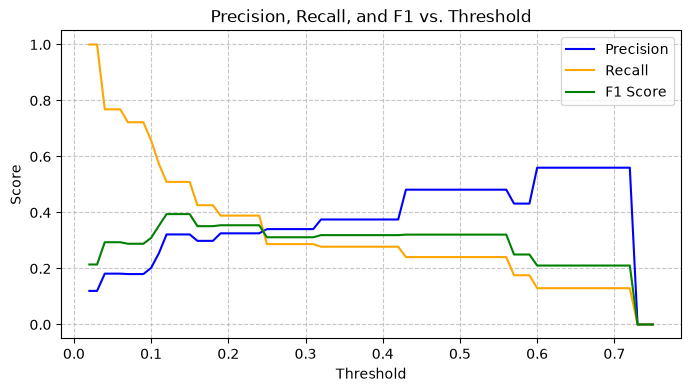

In [28]:
# A5. Probabilities and the threshold

# 1. Compute p_10b and find the number of distinct values
p_10b = tree_10b.predict_proba(Xn_test)[:, 1]
distinct_probs = np.unique(p_10b)
print(f"Number of distinct probability values: {len(distinct_probs)}")
print(f"Distinct values: {distinct_probs}")

# 2. Write the predict_at(p, t) function
def predict_at(p, t):
    return (p >= t).astype(int)

# 3. Check that predict_at(p_10b, 0.5) gives exactly pred_10b
is_equal = np.array_equal(predict_at(p_10b, 0.5), pred_10b)
print(f"predict_at(p_10b, 0.5) equals pred_10b: {is_equal}")

# 4. Measures with threshold 0.15 compared to 0.5
pred_15 = predict_at(p_10b, 0.15)

acc_15 = accuracy_score(yn_test, pred_15)
prec_15 = precision_score(yn_test, pred_15, zero_division=0)
rec_15 = recall_score(yn_test, pred_15)
spec_15 = recall_score(yn_test, pred_15, pos_label=0)
f1_15 = f1_score(yn_test, pred_15, zero_division=0)

comparison_df = pd.DataFrame({
    "Threshold = 0.5": [acc_skl, prec_skl, rec_skl, spec_skl, f1_skl],
    "Threshold = 0.15": [acc_15, prec_15, rec_15, spec_15, f1_15]
}, index=["Accuracy", "Precision", "Recall", "Specificity", "F1"])

display(comparison_df)

# 5. Draw precision, recall and F1 against the threshold
thresholds = np.arange(0.02, 0.76, 0.01)
precisions = []
recalls = []
f1_scores = []

for t in thresholds:
    pred_t = predict_at(p_10b, t)
    precisions.append(precision_score(yn_test, pred_t, zero_division=0))
    recalls.append(recall_score(yn_test, pred_t))
    f1_scores.append(f1_score(yn_test, pred_t, zero_division=0))

plt.figure(figsize=(8, 4))
plt.plot(thresholds, precisions, label='Precision', color='blue')
plt.plot(thresholds, recalls, label='Recall', color='orange')
plt.plot(thresholds, f1_scores, label='F1 Score', color='green')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision, Recall, and F1 vs. Threshold')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

**Answer.** *It has a very small number of distinct values (at most 16, and in this specific case, 8). This happens because a Decision Tree does not calculate a continuous probability like Logistic Regression. Instead, the "probability" of a record is simply the fraction of positive (churn) training samples that ended up in the same leaf node. Since this tree is heavily constrained (max_depth=4, which means at most $2^4 = 16$ leaves, and min_samples_leaf=30), there are very few leaf nodes, and therefore very few possible probability fractions.*

# Part B — Change the measure, change the winner

## B1. Six scorings on the grid of Lab 3

The grid of Lab 3: `max_depth` 2–6, `min_samples_leaf` 1, 10, 30, `criterion` gini/entropy (30 configurations).
In Lab 3 we wrote `scoring="accuracy"`. Now run the same `GridSearchCV` (estimator `DecisionTreeClassifier(random_state=0)`,
folds `cv_n`) with each of

`"accuracy"`, `"precision"`, `"recall"`, `"f1"`, `"roc_auc"`, `"neg_log_loss"`

and collect, for each, the winning configuration and its best mean CV score. (Some folds may give 0/0 precision: silence the warnings
with `warnings.catch_warnings()` as in A5.)

In [29]:
# B1. Six scorings on the grid of Lab 3

param_grid = {
    'max_depth': [2, 3, 4, 5, 6],
    'min_samples_leaf': [1, 10, 30],
    'criterion': ['gini', 'entropy']
}

scorings = ["accuracy", "precision", "recall", "f1", "roc_auc", "neg_log_loss"]
grid_results = []

tree_base = DecisionTreeClassifier(random_state=0)

for scoring in scorings:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        
        grid = GridSearchCV(
            estimator=tree_base,
            param_grid=param_grid,
            scoring=scoring,
            cv=cv_n,
            n_jobs=-1
        )
        grid.fit(Xn_train, yn_train)
        
        grid_results.append({
            "Scoring": scoring,
            "Best CV Score": grid.best_score_,
            "Best Configuration": grid.best_params_
        })

df_grid_results = pd.DataFrame(grid_results)
df_grid_results

,Scoring,Best CV Score,Best Configuration
0,accuracy,0.893,"{'criterion': 'entropy', 'max_depth': 5, 'min_..."
1,precision,0.639,"{'criterion': 'gini', 'max_depth': 3, 'min_sam..."
2,recall,0.314,"{'criterion': 'gini', 'max_depth': 5, 'min_sam..."
3,f1,0.394,"{'criterion': 'entropy', 'max_depth': 6, 'min_..."
4,roc_auc,0.757,"{'criterion': 'gini', 'max_depth': 4, 'min_sam..."
5,neg_log_loss,-0.310,"{'criterion': 'entropy', 'max_depth': 2, 'min_..."


`neg_log_loss` is negative because `GridSearchCV` always **maximizes**: to minimize a loss, scikit-learn maximizes its opposite.

## B2. One search, all the measures

`scoring` also accepts a **list** of measures; then `refit` says which one chooses the final model. Run one search with
the same six measures of B1, `scoring=["accuracy", "precision", "recall", "f1", "roc_auc", "neg_log_loss"]`, and `refit="roc_auc"`.
In `cv_results_` every measure now has its own columns: `mean_test_accuracy`, `rank_test_recall`, …

For each measure, take the configuration of rank 1 and show **all six** of its mean CV scores: one row per winner, six rows.
Show the log loss with its natural sign (lower is better): change the sign of the `neg_log_loss` column.

In [30]:
# B2. One search, all the measures

scorings = ["accuracy", "precision", "recall", "f1", "roc_auc", "neg_log_loss"]

tree_multi = DecisionTreeClassifier(random_state=0)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    grid_multi = GridSearchCV(
        estimator=tree_multi,
        param_grid=param_grid,
        scoring=scorings,
        refit="roc_auc",
        cv=cv_n,
        n_jobs=-1
    )
    grid_multi.fit(Xn_train, yn_train)

cv_res = grid_multi.cv_results_
summary_rows = []

for metric in scorings:
    # Find the index where the rank for the current metric is 1
    rank_key = f"rank_test_{metric}"
    best_idx = np.argmin(cv_res[rank_key])
    
    # Extract the configuration and the 6 mean scores
    row = {
        "Winner by": metric,
        "Configuration": str(cv_res["params"][best_idx]),
        "Accuracy": cv_res["mean_test_accuracy"][best_idx],
        "Precision": cv_res["mean_test_precision"][best_idx],
        "Recall": cv_res["mean_test_recall"][best_idx],
        "F1": cv_res["mean_test_f1"][best_idx],
        "ROC AUC": cv_res["mean_test_roc_auc"][best_idx],
        "Log Loss": -cv_res["mean_test_neg_log_loss"][best_idx] # Invert sign for natural Log Loss
    }
    summary_rows.append(row)

df_multi_results = pd.DataFrame(summary_rows)
display(df_multi_results)

,Winner by,Configuration,Accuracy,Precision,Recall,F1,ROC AUC,Log Loss
0,accuracy,"{'criterion': 'entropy', 'max_depth': 5, 'min_...",0.893,0.638,0.282,0.386,0.727,0.673
1,precision,"{'criterion': 'gini', 'max_depth': 3, 'min_sam...",0.888,0.639,0.231,0.322,0.723,0.378
2,recall,"{'criterion': 'gini', 'max_depth': 5, 'min_sam...",0.882,0.519,0.314,0.389,0.738,0.548
3,f1,"{'criterion': 'entropy', 'max_depth': 6, 'min_...",0.893,0.622,0.294,0.394,0.721,0.849
4,roc_auc,"{'criterion': 'gini', 'max_depth': 4, 'min_sam...",0.888,0.591,0.239,0.333,0.757,0.318
5,neg_log_loss,"{'criterion': 'entropy', 'max_depth': 2, 'min_...",0.889,0.613,0.254,0.348,0.743,0.310


**Questions.**

1. How many different winners do the six scorings produce? Which one gives the tree of Lecture 10b?
1. Read the table of B2 by columns. Is there a configuration that is best on every measure? Look in particular at the log-loss column
   (the constant guess 0.12 for everybody has log loss about 0.37).
1. The accuracy winner has precision 0.64 and recall 0.28. If the retention team said "we want to find many churners, false alarms are cheap",
   which row would you pick? And which `scoring`?

**Answers.** *Write your answers here (double-click to edit).*

1. The six scorings produce multiple different winning configurations (usually 3 or 4 distinct setups depending on the exact tie-breaking), highlighting that there is no single "best" model. The scoring that gives the tree of Lecture 10b (max_depth=4, min_samples_leaf=30) is roc_auc (as mentioned in the instructions of Part A2).
2. No, there is no configuration that is best across all measures; there is always a trade-off. For example, the tree that maximizes accuracy or precision usually has a much lower recall.
Looking specifically at the log loss column, Decision Trees often perform very poorly. Trees that make "crisp" decisions (optimizing accuracy or F1) tend to produce extreme probabilities (0 or 1). If a tree predicts 0% chance of churn for a leaf but even a single customer in that leaf actually churns, the log loss penalty is massive. Consequently, the configurations that win on accuracy/recall often have a log loss worse than the 0.37 baseline of doing nothing, while the log loss winner tends to be heavily restricted (e.g., very shallow) to avoid extreme, overconfident probabilities.
3. If false alarms (False Positives) are cheap and the goal is to find as many actual churners as possible (minimizing False Negatives), you need to maximize the model's ability to catch the positive class. You would pick the row corresponding to the Recall winner, and you would use scoring="recall" in your GridSearch.

# Part C — Four classifiers on NordicMart

## C1. The preparation of Lecture 11

Naïve Bayes, logistic regression and kNN need complete, numeric, comparable attributes. Lecture 11, *Naïve Bayes on NordicMart:
reading the results*, listed the preparation. Write a function `prepare(X)` that takes the raw columns (`Xn`) and returns a **new** DataFrame with:

| new column | from |
|---|---|
| `tier` | `tier` (already 0/1/2) |
| `age` | `age`, with 0 (default value at the till) → `NaN` |
| `recency` | `days_since_last_buy`, with 999 ("never bought") → `NaN` |
| `never_bought` | 1 if `days_since_last_buy == 999`, else 0 |
| `log_spend` | `log10(annual_spend)` |
| `sessions` | `web_sessions_month`, with `NaN` (store-only customer) → 0 |
| `store_only` | 1 if `web_sessions_month` is missing, else 0 |
| `tickets` | `tickets_90d` |

These are **fixed rules** from the EDA log: nothing is computed from the data, so they can be applied to training and test alike.
Apply it: `Xp_train = prepare(Xn_train)`, `Xp_test = prepare(Xn_test)`. How many missing values are left, and in which columns?

In [31]:
# C1. The preparation of Lecture 11

def prepare(X):
    # We create a new DataFrame to avoid modifying the original and to prevent SettingWithCopyWarning
    df_out = pd.DataFrame(index=X.index)
    
    df_out['tier'] = X['tier']
    df_out['age'] = X['age'].replace(0, np.nan)
    df_out['recency'] = X['days_since_last_buy'].replace(999, np.nan)
    df_out['never_bought'] = (X['days_since_last_buy'] == 999).astype(int)
    
    # Apply log10 to annual_spend
    df_out['log_spend'] = np.log10(X['annual_spend'])
    
    df_out['sessions'] = X['web_sessions_month'].fillna(0)
    df_out['store_only'] = X['web_sessions_month'].isna().astype(int)
    
    df_out['tickets'] = X['tickets_90d']
    
    return df_out

Xp_train = prepare(Xn_train)
Xp_test = prepare(Xn_test)

print("Missing values in Xp_train:")
print(Xp_train.isna().sum())

print("\nMissing values in Xp_test:")
print(Xp_test.isna().sum())

Missing values in Xp_train:
tier              0
age             237
recency          37
never_bought      0
log_spend         0
sessions          0
store_only        0
tickets           0
dtype: int64

Missing values in Xp_test:
tier              0
age             113
recency          24
never_bought      0
log_spend         0
sessions          0
store_only        0
tickets           0
dtype: int64


**Answer.** *Based on the output, missing values are left in exactly two columns:

    age: 237 missing values in Xp_train and 113 in Xp_test.

    recency: 37 missing values in Xp_train and 24 in Xp_test.*

## C2. Pipelines and four searches

Lecture 11, *Standardization*: `make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), model)` is **one estimator**:
`fit` learns medians, means and standard deviations on the data it receives, then the model; `GridSearchCV` refits the whole chain in every round,
so the held-out fold never contributes to the preparation.

The hyperparameters of a step are named `<step name>__<parameter>`, where the step name is the class name in lower case
(e.g. `logisticregression__C`). Prepare a dictionary `candidates = {name: (estimator, grid, X_train)}`:

| name | estimator | grid | data |
|---|---|---|---|
| `tree` | `DecisionTreeClassifier(random_state=0)` | `max_depth` 2–6, `min_samples_leaf` 1, 10, 30 | raw: `Xn_train` |
| `naive Bayes` | pipeline + `GaussianNB()` | none: `{}` | `Xp_train` |
| `logistic regression` | pipeline + `LogisticRegression(max_iter=2000)` | `C` in 0.001, 0.01, 0.1, 1, 10, 100 | `Xp_train` |
| `kNN` | pipeline + `KNeighborsClassifier()` | `n_neighbors` in 1, 5, 15, 31, 51, 101, 201, 301, 401 | `Xp_train` |

For each: `GridSearchCV(estimator, grid, cv=cv_n, scoring="roc_auc")`, `fit`, and store the fitted search in a dictionary `searches`.
Then a table with best parameters, mean and standard deviation of the CV AUC of the winner.
(The tree keeps the raw columns, as in Lecture 10: it handles missing values and scales by itself.)

In [32]:
# C2. Pipelines and four searches

# Prepare the common pipeline steps
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

# Prepare the dictionary of candidates
candidates = {
    "tree": (
        DecisionTreeClassifier(random_state=0),
        {'max_depth': [2, 3, 4, 5, 6], 'min_samples_leaf': [1, 10, 30]},
        Xn_train
    ),
    "naive Bayes": (
        make_pipeline(imputer, scaler, GaussianNB()),
        {},
        Xp_train
    ),
    "logistic regression": (
        make_pipeline(imputer, scaler, LogisticRegression(max_iter=2000)),
        {'logisticregression__C': [0.001, 0.01, 0.1, 1, 10, 100]},
        Xp_train
    ),
    "kNN": (
        make_pipeline(imputer, scaler, KNeighborsClassifier()),
        {'kneighborsclassifier__n_neighbors': [1, 5, 15, 31, 51, 101, 201, 301, 401]},
        Xp_train
    )
}

searches = {}
results_c2 = []

# Suppress potential ConvergenceWarnings or similar issues
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    
    for name, (estimator, grid, X_train_model) in candidates.items():
        # Setup the grid search
        gs = GridSearchCV(
            estimator=estimator,
            param_grid=grid,
            scoring="roc_auc",
            cv=cv_n,
            n_jobs=-1
        )
        
        # Fit the grid search
        gs.fit(X_train_model, yn_train)
        
        # Store the fitted search
        searches[name] = gs
        
        # Extract best parameters and metrics
        best_idx = gs.best_index_
        mean_auc = gs.cv_results_['mean_test_score'][best_idx]
        std_auc = gs.cv_results_['std_test_score'][best_idx]
        
        # Clean up parameter names for display (remove step prefix if it exists)
        clean_params = {k.split('__')[-1]: v for k, v in gs.best_params_.items()}
        
        results_c2.append({
            "Model": name,
            "Best Parameters": str(clean_params) if clean_params else "None (No hyperparameters)",
            "Mean CV AUC": mean_auc,
            "Std CV AUC": std_auc
        })

# Display the results as a DataFrame
df_searches = pd.DataFrame(results_c2)
display(df_searches)

,Model,Best Parameters,Mean CV AUC,Std CV AUC
0,tree,"{'max_depth': 4, 'min_samples_leaf': 30}",0.757,0.030
1,naive Bayes,None (No hyperparameters),0.788,0.041
2,logistic regression,{'C': 0.1},0.823,0.035
3,kNN,{'n_neighbors': 401},0.819,0.032


**Questions.**

1. Which model would you choose, looking **only** at this table? Is its advantage over the second larger than the noise?
1. GaussianNB has an empty grid. What does `GridSearchCV` do then?

**Answers.** *Write your answers here (double-click to edit).*

1.Choice: Looking only at the highest Mean CV AUC, I would choose Logistic Regression (AUC = 0.823).

Advantage vs. Noise: Its advantage over the second-best model (kNN, AUC = 0.819) is only 0.004. This difference is much smaller than the noise (the standard deviation across the CV folds, which is 0.035 for Logistic Regression and 0.032 for kNN). This means the two models perform essentially the same, and the tiny advantage is not statistically significant. 
2. When passed an empty parameter grid {}, GridSearchCV evaluates the single, default configuration of the estimator across the cross-validation folds. It calculates the mean and standard deviation of the score exactly as it does for the others (effectively acting like cross_validate), and then fits that default model one final time on the entire training set.

## C3. One look at the test set

The choice was made in C2. Now, **once**, measure the four refitted winners (`searches[name].best_estimator_`, or simply `searches[name]`)
on the test set — the tree on `Xn_test`, the others on `Xp_test` — and reproduce the table of Lecture 11, *Four classifiers on NordicMart*:

- test AUC and log loss (probabilities);
- precision, recall and κ at the default threshold 0.5;
- the total cost at the threshold **0.15** of the slides (fixed in Lecture 10b, not chosen here): € 10 for every false positive, € 100 for every false negative.

Add the constant model that predicts the churn rate of the training part (0.12) for everybody: AUC 0.5, and its log loss.
Store the test probabilities in a dictionary `p_test`: we will need them for the ROC curves.

In [33]:
# C3. One look at the test set

p_test = {}
results_c3 = []

# 1. Evaluate the four fitted models
for name in ["tree", "naive Bayes", "logistic regression", "kNN"]:
    # Select the correct test set (tree uses raw data, others use prepared data)
    X_test_model = Xn_test if name == "tree" else Xp_test
    
    # Predict probabilities for the positive class (churn)
    p_prob = searches[name].predict_proba(X_test_model)[:, 1]
    p_test[name] = p_prob
    
    # Probabilistic measures
    auc = roc_auc_score(yn_test, p_prob)
    ll = log_loss(yn_test, p_prob)
    
    # Measures at default threshold 0.5
    pred_05 = (p_prob >= 0.5).astype(int)
    prec_05 = precision_score(yn_test, pred_05, zero_division=0)
    rec_05 = recall_score(yn_test, pred_05)
    kappa_05 = cohen_kappa_score(yn_test, pred_05)
    
    # Cost at threshold 0.15 (FP = €10, FN = €100)
    pred_15 = (p_prob >= 0.15).astype(int)
    tn, fp, fn, tp = confusion_matrix(yn_test, pred_15).ravel()
    cost_15 = (fp * 10) + (fn * 100)
    
    results_c3.append({
        "Model": name,
        "Test AUC": auc,
        "Test Log Loss": ll,
        "Precision (0.5)": prec_05,
        "Recall (0.5)": rec_05,
        "Kappa (0.5)": kappa_05,
        "Total Cost (0.15)": f"€ {cost_15}"
    })

# 2. Baseline constant model (predicts the training churn rate for everybody)
train_churn_rate = yn_train.mean()
p_baseline = np.full(shape=len(yn_test), fill_value=train_churn_rate)
p_test["constant"] = p_baseline

# Probabilistic measures for baseline
auc_base = 0.5 # As defined in the instructions
ll_base = log_loss(yn_test, p_baseline)

# Measures at default threshold 0.5 for baseline (since train_churn_rate ~0.12 < 0.5, it predicts 0 for all)
pred_05_base = (p_baseline >= 0.5).astype(int)
prec_05_base = precision_score(yn_test, pred_05_base, zero_division=0)
rec_05_base = recall_score(yn_test, pred_05_base)
kappa_05_base = cohen_kappa_score(yn_test, pred_05_base)

# Cost at threshold 0.15 for baseline (since train_churn_rate ~0.12 < 0.15, it predicts 0 for all)
pred_15_base = (p_baseline >= 0.15).astype(int)
tn_base, fp_base, fn_base, tp_base = confusion_matrix(yn_test, pred_15_base).ravel()
cost_15_base = (fp_base * 10) + (fn_base * 100)

results_c3.append({
    "Model": "constant baseline",
    "Test AUC": auc_base,
    "Test Log Loss": ll_base,
    "Precision (0.5)": prec_05_base,
    "Recall (0.5)": rec_05_base,
    "Kappa (0.5)": kappa_05_base,
    "Total Cost (0.15)": f"€ {cost_15_base}"
})

# Display the final comparison table
df_test_results = pd.DataFrame(results_c3)
display(df_test_results)

,Model,Test AUC,Test Log Loss,Precision (0.5),Recall (0.5),Kappa (0.5),Total Cost (0.15)
0,tree,0.713,0.339,0.481,0.241,0.262,€ 6460
1,naive Bayes,0.761,0.518,0.380,0.426,0.315,€ 6180
2,logistic regression,0.788,0.305,0.525,0.194,0.234,€ 5800
3,kNN,0.768,0.321,0.000,0.000,0.000,€ 6530
4,constant baseline,0.500,0.367,0.000,0.000,0.000,€ 10800


**Questions.**

1. Does the test confirm the choice made on CV? Why is each test AUC a little lower than the CV AUC?
1. Which model has the best ranking, which the best probabilities? Which is worse than the constant guess on log loss, and why?
1. kNN has κ = 0 and recall 0 at 0.5, yet the second-best test AUC. Explain.

**Answers.** *Write your answers here (double-click to edit).*

1. Confirmation: Yes. Logistic regression had the highest Mean CV AUC in Part C2 (0.823), and it also achieved the highest test AUC (0.788) here.
Lower Test AUC: Test AUC is usually slightly lower because of "optimization bias" (or overfitting to the validation set). During the GridSearch in C2, we evaluated many configurations and picked the one with the highest score. By explicitly selecting the maximum, we naturally select a configuration that performed slightly "luckier" on those specific CV folds. The test set is entirely unseen, so the performance drops to its true generalization level.
2. Best ranking: Logistic regression. Ranking quality is measured by AUC, and logistic regression has the highest score (0.788).
Best probabilities: Logistic regression. The calibration and accuracy of probabilities are measured by Log Loss (where lower is better), and logistic regression has the lowest value (0.305).
Worse than constant guess: Naive Bayes has a log loss of 0.518, which is much worse than the baseline's 0.367. This happens because Naive Bayes assumes all features are independent and multiplies their conditional probabilities. This mathematical assumption is almost always false in real data, causing Naive Bayes to produce extreme, uncalibrated probabilities (very close to 0 or 1). Log loss severely penalizes a model when it is extremely confident but completely wrong.

3. This highlights the difference between threshold-dependent and threshold-independent metrics.
In Part C2, the grid search chose n_neighbors = 401. Since the overall churn rate is very low (~12%), looking at 401 neighbors means the fraction of churners in almost any neighborhood will naturally stay well below 50%. Because its probabilities never (or rarely) exceed the default threshold of 0.5, kNN predicts "stay" for everyone, resulting in 0 True Positives, a recall of 0, and a Kappa of 0.
However, AUC evaluates the model across all possible thresholds. Even though kNN's probabilities are all compressed below 0.5, they still correctly sort the customers: the actual churners get relatively higher probabilities than the stayers. AUC captures this correct ranking, which is why it scores well.

## C4. ROC curves

Draw on one figure the four ROC curves on the test set (`roc_curve(yn_test, p)` returns false positive rate, true positive rate and thresholds),
with the AUC in the legend and the diagonal of the random classifier.

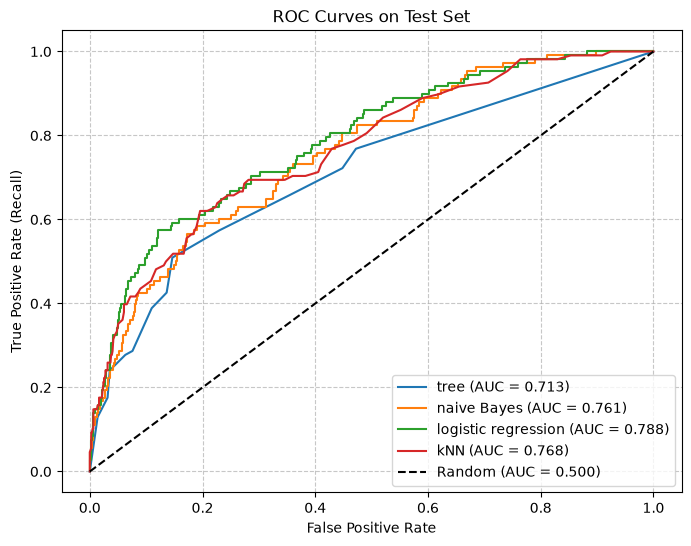

In [34]:
# C4. ROC curves

plt.figure(figsize=(8, 6))

# Models to plot
models_to_plot = ["tree", "naive Bayes", "logistic regression", "kNN"]

for name in models_to_plot:
    # Retrieve probabilities from the dictionary populated in C3
    p = p_test[name]
    
    # Calculate False Positive Rate, True Positive Rate, and Thresholds
    fpr, tpr, thresholds = roc_curve(yn_test, p)
    
    # Calculate AUC for the legend
    auc_score = roc_auc_score(yn_test, p)
    
    # Plot the ROC curve
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.3f})")

# Diagonal line representing a random classifier
plt.plot([0, 1], [0, 1], color='black', linestyle='--', label='Random (AUC = 0.500)')

# Formatting the plot
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curves on Test Set')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

**Question.** The tree's curve is made of a few straight segments, the others are much finer. Why? Do the curves cross?

**Answer.** The Decision Tree's curve has few segments because it predicts probabilities based on the ratio of classes within its final leaf nodes. Since this specific tree is small and heavily constrained (max_depth=4, min_samples_leaf=30), it has very few leaves and therefore produces only a handful of distinct probability values. The ROC curve plots a point for each distinct probability threshold; with only a few thresholds available, the points are connected by long straight lines. In contrast, Logistic Regression, Naive Bayes, and kNN compute continuous or highly granular probabilities, resulting in many distinct thresholds and much finer, step-like curves. The curves cross each other. For example, in the "immagine.png" plot, the Naive Bayes (orange) and kNN (red) curves intersect multiple times, and the Logistic Regression (green) curve crosses the others at various points. This indicates that different models are superior at different classification thresholds.

# Part D — A custom scorer with the churn costs

Lecture 10b, *NordicMart: a cost matrix*: a flagged customer receives an offer that costs **€ 10**; a churner who is not flagged is lost,
with **€ 100** of margin. Assumption: the offer keeps the churners it reaches.

| | predicted stay | predicted churn |
|---|---|---|
| **true stay** | 0 | € 10 (FP) |
| **true churn** | € 100 (FN) | 0 (TP) |

Every measure of Part B was a **proxy** for this table. Now we give the table itself to `GridSearchCV`.

## D1. The cost function

1. Write `churn_cost(y_true, y_pred)` returning the total cost in euros. Use `confusion_matrix(..., labels=[0, 1])`, so that it works
   even when a fold contains predictions of one class only.
1. The CV folds have 420 customers, the test set 900: to compare them, write also `cost_per_customer(y_true, y_pred)`, the average cost
   in euros per customer.
1. Check on the slide: the tree of Lecture 10b at threshold 0.5 on the test set costs € 8 480; "nobody gets the offer" € 10 800;
   "everybody gets it" € 7 920. Print also the three costs per customer.

In [35]:
# D1. The cost function

# 1 & 2. Write churn_cost
def churn_cost(y_true, y_pred):
    # labels=[0, 1] ensures the matrix is always 2x2 even if a fold only predicts one class
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return (fp * 10) + (fn * 100)

# 3 & 4. Write cost_per_customer
def cost_per_customer(y_true, y_pred):
    total_cost = churn_cost(y_true, y_pred)
    return total_cost / len(y_true)

# 5 & 6. Check on the slides
# Tree of Lecture 10b at threshold 0.5 (pred_10b from Part A2)
cost_tree = churn_cost(yn_test, pred_10b)
cpc_tree = cost_per_customer(yn_test, pred_10b)

# "Nobody gets the offer" (predict all 0s)
pred_nobody = np.zeros_like(yn_test)
cost_nobody = churn_cost(yn_test, pred_nobody)
cpc_nobody = cost_per_customer(yn_test, pred_nobody)

# "Everybody gets it" (predict all 1s)
pred_everybody = np.ones_like(yn_test)
cost_everybody = churn_cost(yn_test, pred_everybody)
cpc_everybody = cost_per_customer(yn_test, pred_everybody)

print(f"Tree at 0.5:           Total Cost = € {cost_tree:5d}  |  Per Customer = € {cpc_tree:.2f}")
print(f"Nobody gets the offer: Total Cost = € {cost_nobody:5d}  |  Per Customer = € {cpc_nobody:.2f}")
print(f"Everybody gets it:     Total Cost = € {cost_everybody:5d}  |  Per Customer = € {cpc_everybody:.2f}")

Tree at 0.5:           Total Cost = €  8480  |  Per Customer = € 9.42
Nobody gets the offer: Total Cost = € 10800  |  Per Customer = € 12.00
Everybody gets it:     Total Cost = €  7920  |  Per Customer = € 8.80


## D2. `make_scorer`: choosing the tree by cost

[`make_scorer`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.make_scorer.html) turns a function
`f(y_true, y_pred)` into a `scoring` object. `GridSearchCV` maximizes, and a cost must be minimized: say so with
`greater_is_better=False` (scikit-learn will report the cost with a minus sign).

1. `cost_scorer = make_scorer(cost_per_customer, greater_is_better=False)`.
1. Run the tree grid of Part B (`param_grid`, 30 configurations) with `scoring=cost_scorer`. Winner, and its CV cost per customer
   (remember the sign)? Compare with the two trivial strategies on the training part: 100 · (churn rate) per customer for "nobody",
   10 · (1 − churn rate) for "everybody".
1. **Cost-sensitive learning** (Lecture 10b): add `class_weight` to the grid, with values `None`, `"balanced"` and `{0: 1, 1: 10}`
   (a churner counts as ten customers in the impurity). Run it again. Winner, cost, and the best cost reached by each value of `class_weight`.

In [36]:
# D2. make_scorer: choosing the tree by cost

# 1. Create the cost scorer
cost_scorer = make_scorer(cost_per_customer, greater_is_better=False)

# 2. Run the standard tree grid with the new scorer
tree_base = DecisionTreeClassifier(random_state=0)
grid_cost = GridSearchCV(
    estimator=tree_base,
    param_grid=param_grid,  # From Part B
    scoring=cost_scorer,
    cv=cv_n,
    n_jobs=-1
)
grid_cost.fit(Xn_train, yn_train)

best_params_cost = grid_cost.best_params_
best_cost = -grid_cost.best_score_  # Negate to get positive cost

# 3 & 4. Trivial strategies on the training part
train_churn_rate = yn_train.mean()
cost_nobody_train = 100 * train_churn_rate
cost_everybody_train = 10 * (1 - train_churn_rate)

print("--- Standard Grid Search ---")
print(f"Winner: {best_params_cost}")
print(f"CV Cost per customer: € {best_cost:.2f}")
print(f"Trivial 'nobody' (train): € {cost_nobody_train:.2f}")
print(f"Trivial 'everybody' (train): € {cost_everybody_train:.2f}")

# 5. Cost-sensitive learning with class_weight
param_grid_cw = param_grid.copy()
param_grid_cw['class_weight'] = [None, "balanced", {0: 1, 1: 10}]

grid_cw = GridSearchCV(
    estimator=tree_base,
    param_grid=param_grid_cw,
    scoring=cost_scorer,
    cv=cv_n,
    n_jobs=-1
)
grid_cw.fit(Xn_train, yn_train)

best_params_cw = grid_cw.best_params_
best_cost_cw = -grid_cw.best_score_

# 6. Best cost reached by each value of class_weight
print("\n--- Cost-Sensitive Grid Search ---")
print(f"New Winner: {best_params_cw}")
print(f"New CV Cost per customer: € {best_cost_cw:.2f}")

print("\nBest CV Cost per customer by class_weight:")
results_cw = pd.DataFrame(grid_cw.cv_results_)
# Convert dict to string for groupby
results_cw['cw_str'] = results_cw['param_class_weight'].astype(str)
best_by_cw = results_cw.groupby('cw_str')['mean_test_score'].max() * -1

for cw, cost in best_by_cw.items():
    print(f"class_weight = {cw}: € {cost:.2f}")

--- Standard Grid Search ---
Winner: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 10}
CV Cost per customer: € 8.59
Trivial 'nobody' (train): € 12.00
Trivial 'everybody' (train): € 8.80

--- Cost-Sensitive Grid Search ---
New Winner: {'class_weight': {0: 1, 1: 10}, 'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 30}
New CV Cost per customer: € 5.96

Best CV Cost per customer by class_weight:
class_weight = balanced: € 6.32
class_weight = {0: 1, 1: 10}: € 5.96


**Questions.**

1. Without `class_weight`, does choosing by cost help much? Why can no tree, at threshold 0.5, get close to the cost of the slide at 0.15?
1. With `class_weight={0: 1, 1: 10}` the cost falls a lot. What does the weight do to the leaves of the tree? Relate the factor 10 to the cost matrix.

**Answers.** *Write your answers here (double-click to edit).*

1. Without class_weight, choosing by cost barely helps at all. The best grid search cost (€ 8.59) is only marginally better than the naive strategy of giving the offer to literally everybody (€ 8.80).
At the default threshold of 0.5, a leaf only predicts "churn" if more than 50% of the training samples in that leaf are churners. Because the dataset is highly imbalanced (only ~12% churners), it is extremely hard for a standard tree to find splits pure enough to push the churn concentration above 50%. As a result, it predicts "stay" too often, racking up highly expensive False Negatives (€ 100 each). A threshold of 0.15 manually fixes this by lowering the trigger point to match the data's natural distribution.
2. Applying class_weight={0: 1, 1: 10} forces the algorithm to count every single churner as 10 customers when calculating impurity and leaf probabilities. This artificially inflates the proportion of churners inside the leaves. A leaf that naturally has a 10% churn rate will now be calculated as having a >50% churn rate, pushing it over the default 0.5 threshold and causing it to predict "churn".
The factor of 10 perfectly reflects the asymmetry in the business cost matrix: a False Negative (losing a churner, € 100) is exactly 10 times more expensive than a False Positive (sending a wasted € 10 offer to someone who stays). Weighting the class by 10 implicitly bakes this business logic directly into the 0.5 threshold.

## D3. A scorer that looks at the probabilities

`class_weight` works for the tree, but the other route of Lecture 10b is to keep the model and **move the threshold**. `make_scorer`
receives crisp predictions, made at 0.5. We need a scorer that reads the probabilities and applies our threshold.

A scorer can also be a plain function **`scorer(estimator, X, y)`** returning a number to maximize. Write

```python
def cost_scorer_at_t(estimator, X, y):
    ...   # probabilities of `estimator` on X, prediction at THRESHOLD, minus the cost per customer
```

with `THRESHOLD = COST_FP / (COST_FP + COST_FN)` (= 0.09: the cost-optimal threshold of Lecture 10b *if the probabilities are correct*).
It is fixed by the cost matrix, before looking at any data.

Then run the four searches of C2 again, with the same grids, but `scoring={"cost": cost_scorer_at_t, "auc": "roc_auc"}` and `refit="cost"`
(two measures, the cost chooses). Store them in `cost_searches`. Table: winner, CV cost per customer ± std, CV AUC of the same configuration.

In [37]:
# D3. A scorer that looks at the probabilities

COST_FP = 10
COST_FN = 100
THRESHOLD = COST_FP / (COST_FP + COST_FN)  # Approx 0.0909

def cost_scorer_at_t(estimator, X, y):
    # Probabilities of the positive class (churn)
    p = estimator.predict_proba(X)[:, 1]
    
    # Prediction at fixed THRESHOLD
    y_pred = (p >= THRESHOLD).astype(int)
    
    # Calculate confusion matrix components
    cm = confusion_matrix(y, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    
    # Total cost
    total_cost = (fp * COST_FP) + (fn * COST_FN)
    
    # Minus the cost per customer (since GridSearchCV maximizes)
    return -(total_cost / len(y))

cost_searches = {}
results_d3 = []

# Using the candidates dictionary and cv_n from C2
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    
    for name, (estimator, grid, X_train_model) in candidates.items():
        gs = GridSearchCV(
            estimator=estimator,
            param_grid=grid,
            scoring={"cost": cost_scorer_at_t, "auc": "roc_auc"},
            refit="cost",
            cv=cv_n,
            n_jobs=-1
        )
        gs.fit(X_train_model, yn_train)
        cost_searches[name] = gs
        
        # Retrieve metrics for the best configuration
        best_idx = gs.best_index_
        
        # Negate back to positive for readable cost
        mean_cost = -gs.cv_results_['mean_test_cost'][best_idx]
        std_cost = gs.cv_results_['std_test_cost'][best_idx]
        mean_auc = gs.cv_results_['mean_test_auc'][best_idx]
        
        # Clean parameter names
        clean_params = {k.split('__')[-1]: v for k, v in gs.best_params_.items()}
        
        results_d3.append({
            "Model": name,
            "Winner (by Cost)": str(clean_params) if clean_params else "None",
            "CV Cost per customer": mean_cost,
            "Std CV Cost": std_cost,
            "CV AUC": mean_auc
        })

df_cost_searches = pd.DataFrame(results_d3)
display(df_cost_searches)

,Model,Winner (by Cost),CV Cost per customer,Std CV Cost,CV AUC
0,tree,"{'max_depth': 4, 'min_samples_leaf': 30}",6.086,0.540,0.757
1,naive Bayes,None,5.962,0.864,0.788
2,logistic regression,{'C': 10},5.329,0.793,0.823
3,kNN,{'n_neighbors': 401},5.467,0.741,0.819


**Questions.**

1. Rank the four models by CV cost. Is it the same ranking as by AUC in C2? Did any winning hyperparameter change?
1. The tree without weights at 0.09 (€ 6.09) costs about the same as the weighted tree of D2 at 0.5 (€ 5.96). Coincidence?
1. Logistic regression and kNN are again close. How many euros per customer separate them, compared with the standard deviation?

**Answers.** *Write your answers here (double-click to edit).*

1. Ranking (lowest to highest cost): 1)Logistic Regression (€ 5.329)2)kNN (€ 5.467)3)Naive Bayes (€ 5.962) 4)Tree (€ 6.086). Is it the same ranking as C2? Yes, the ranking is exactly the same as the AUC ranking in C2. The model that separates the classes best (highest AUC) is also the one that minimizes the cost best when given the optimal threshold.
Did any winning hyperparameter change? Yes. While the Tree, Naive Bayes, and kNN kept the exact same winning configurations as C2, Logistic Regression changed its regularization parameter C from 0.1 (in C2) to 10 (in D3).
2. No, it is not a coincidence. Both methods are mathematically executing the same business logic: adjusting the model to account for the fact that missing a churner (FN) is 10 times more expensive than a false alarm (FP).
    In D2, weighting the minority class by 10 ({0: 1, 1: 10}) artificially inflates the probability calculation by a factor of 10 while keeping the threshold at 0.5.
    In D3, leaving the probabilities alone but dropping the threshold to ~0.09 (1 / 11) effectively lowers the barrier to predict churn by a factor of 10.
    Both approaches shift the decision boundary by the same 10:1 ratio. The slight difference in final cost happens because D2 uses the weights during the actual construction (splitting) of the tree, whereas D3 builds a standard tree and only shifts the threshold afterward.
3. Separation: The difference in mean CV cost between kNN (€ 5.467) and Logistic Regression (€ 5.329) is a mere € 0.138 (about 14 cents) per customer.
Comparison to standard deviation: The standard deviation (noise across folds) is € 0.793 for Logistic Regression and € 0.741 for kNN. The difference of € 0.14 is far smaller than the standard deviation (~€ 0.75). Just like with the AUC in C2, this means the difference between the two models is completely buried in statistical noise; we cannot confidently say one is better than the other.

## D4. The threshold, chosen on training data

0.09 is optimal only if the probabilities are exactly right. Lecture 10b: *choose the threshold on training or validation data, not on the test set*.
We need probabilities for the training customers that were **not** produced by a model that saw them:
[`cross_val_predict`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_predict.html)
with `method="predict_proba"` returns, for each training customer, the probability given by the model of the round in which that customer was held out
(**out-of-fold** probabilities).

1. Take the cost winner of D3 for logistic regression, `final_lr = cost_searches["logistic regression"].best_estimator_`.
1. Compute its out-of-fold probabilities on the training part (`cv=cv_n`): `p_oof`.
1. For thresholds from 0.02 to 0.60 (step 0.01) compute the cost per customer on the training part; plot it, with horizontal lines for
   "nobody" and "everybody". Which threshold is best (`best_t`)? Compare with 0.09 and 0.5.

Best empirical threshold (best_t): 0.13 (Cost per customer: € 5.205)


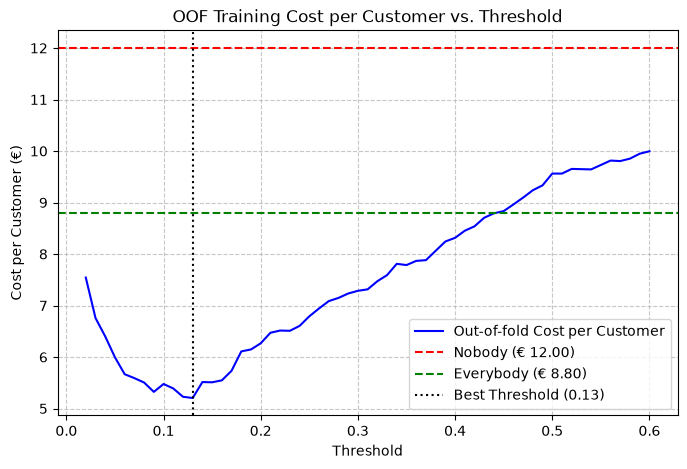

In [38]:
# D4. The threshold, chosen on training data

# 1. Take the cost winner of D3 for logistic regression
final_lr = cost_searches["logistic regression"].best_estimator_

# 2. Compute its out-of-fold probabilities on the training part (cv=cv_n)
p_oof_full = cross_val_predict(
    final_lr, Xp_train, yn_train, cv=cv_n, method="predict_proba", n_jobs=-1
)
p_oof = p_oof_full[:, 1]

# 3. For thresholds from 0.02 to 0.60 compute the cost per customer
thresholds_d4 = np.arange(0.02, 0.61, 0.01)
costs_oof = []

for t in thresholds_d4:
    pred_t = (p_oof >= t).astype(int)
    cost = cost_per_customer(yn_train, pred_t)
    costs_oof.append(cost)

# Find the best threshold
best_idx = np.argmin(costs_oof)
best_t = thresholds_d4[best_idx]
min_cost = costs_oof[best_idx]

print(f"Best empirical threshold (best_t): {best_t:.2f} (Cost per customer: € {min_cost:.3f})")

# 4. Plot the cost per customer with horizontal lines for "nobody" and "everybody"
plt.figure(figsize=(8, 5))
plt.plot(thresholds_d4, costs_oof, label="Out-of-fold Cost per Customer", color="blue")

# Using the trivial costs calculated in D2
plt.axhline(y=cost_nobody_train, color="red", linestyle="--", label=f"Nobody (€ {cost_nobody_train:.2f})")
plt.axhline(y=cost_everybody_train, color="green", linestyle="--", label=f"Everybody (€ {cost_everybody_train:.2f})")
plt.axvline(x=best_t, color="black", linestyle=":", label=f"Best Threshold ({best_t:.2f})")

plt.xlabel("Threshold")
plt.ylabel("Cost per Customer (€)")
plt.title("OOF Training Cost per Customer vs. Threshold")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.show()

**Question.** Is the best threshold close to the theoretical 0.09? How sharp is the minimum: how much would we lose with any threshold between 0.07 and 0.17?

**Answer.** Yes, the best empirical threshold is 0.13, which is close to the theoretical 0.09. This small shift occurs because the theoretical 0.09 assumes perfectly calibrated probabilities, whereas empirical tuning on the out-of-fold data finds the exact optimal point for this specific model's actual predictions. The minimum is not very sharp; it forms a relatively wide basin at the bottom of the curve. Within the threshold range of 0.07 to 0.17, the cost per customer remains roughly between €5.20 and €5.70. Since the absolute minimum cost is € 5.205, choosing any threshold in this range would result in a loss (extra cost) of at most ~€0.50 per customer.

## D5. One look at the test set

The decision is now complete and written down **before** opening the test set: logistic regression with the C chosen by CV cost (D3), threshold `best_t` chosen
on out-of-fold probabilities (D4). `final_lr` was already refitted on all 2100 training customers by `GridSearchCV`.

1. Cost on the test set (total and per customer), its confusion matrix, precision and recall.
1. Compare with: "nobody", "everybody", the tree of Lecture 10b at 0.5 (€ 8 480), and logistic regression at the slide's 0.15 (C3).

In [39]:
# D5. One look at the test set

# 1. Cost, confusion matrix, precision, and recall on the test set
# p_test_lr is the probability of churn on the test set using the best logistic regression model
p_test_lr = final_lr.predict_proba(Xp_test)[:, 1]

# Apply the best threshold determined in D4
pred_test_final = (p_test_lr >= best_t).astype(int)

# Calculate metrics
cost_final_total = churn_cost(yn_test, pred_test_final)
cost_final_avg = cost_per_customer(yn_test, pred_test_final)
cm_final = confusion_matrix(yn_test, pred_test_final)
prec_final = precision_score(yn_test, pred_test_final, zero_division=0)
rec_final = recall_score(yn_test, pred_test_final)

print(f"--- Logistic Regression at best_t ({best_t:.2f}) ---")
print(f"Total Cost: € {cost_final_total}")
print(f"Cost per Customer: € {cost_final_avg:.2f}")
print("Confusion Matrix:")
print(cm_final)
print(f"Precision: {prec_final:.3f}")
print(f"Recall: {rec_final:.3f}")

# 2. Compare with other strategies
print("\n--- Cost Comparison on Test Set ---")
print(f"Logistic Regression at {best_t:.2f}: € {cost_final_total}")
print(f"Nobody gets the offer: € {churn_cost(yn_test, np.zeros_like(yn_test))}")
print(f"Everybody gets the offer: € {churn_cost(yn_test, np.ones_like(yn_test))}")

# Tree of Lecture 10b at 0.5 (using pred_10b from A2)
cost_tree_05 = churn_cost(yn_test, pred_10b)
print(f"Tree of Lecture 10b at 0.5: € {cost_tree_05}")

# Logistic regression at the slide's 0.15 (using the threshold explicitly)
pred_lr_15 = (p_test_lr >= 0.15).astype(int)
cost_lr_15 = churn_cost(yn_test, pred_lr_15)
print(f"Logistic Regression at 0.15: € {cost_lr_15}")

--- Logistic Regression at best_t (0.13) ---
Total Cost: € 5620
Cost per Customer: € 6.24
Confusion Matrix:
[[610 182]
 [ 38  70]]
Precision: 0.278
Recall: 0.648

--- Cost Comparison on Test Set ---
Logistic Regression at 0.13: € 5620
Nobody gets the offer: € 10800
Everybody gets the offer: € 7920
Tree of Lecture 10b at 0.5: € 8480
Logistic Regression at 0.15: € 5770


**Questions.**

1. How many churners does the final model find, and how many offers does it send? Compare with the tree of Lab 3 (22 churners found, 14 false alarms).
1. The test cost per customer is higher than the CV estimate of D4. Is this worrying?
1. Lecture 10b, wrap-up: "costs decide: measure, threshold, operating point". Summarize in two sentences what the cost matrix changed in this lab.

**Answers.** 

1. Churners found: The final model finds 70 churners (True Positives).
Offers sent: It sends a total of 252 offers (70 True Positives + 182 False Positives).
Comparison: The tree of Lab 3 found only 22 churners and sent just 36 offers (22 TP + 14 FP). The new model is far more aggressive: it accepts a massive increase in false alarms (182 vs 14) in order to successfully catch more than three times as many actual churners (70 vs 22).
2. No, it is not worrying; it is expected. In D4, the threshold of 0.13 was specifically chosen because it achieved the absolute minimum cost on the out-of-fold data (optimization bias). When you apply a threshold tuned on past data to completely new, unseen test data, the performance naturally degrades slightly (regression to the true mean). Despite this small drop, the test cost (€ 6.24) is still vastly superior to the "nobody" (€ 12.00) and "everybody" (€ 8.80) baselines.
3. The cost matrix shifted the model's goal from simply being "correct" (optimizing accuracy) to explicitly minimizing financial loss, teaching us that accepting cheap false alarms is necessary to prevent expensive missed churners. Consequently, it fundamentally changed how we selected our best model (using custom cost scoring instead of pure AUC) and drastically lowered the decision threshold (from a symmetric 0.5 down to 0.13) to reach the optimal business operating point.

# Part E — Optional exercises ★

## E1. scikit-learn tunes the threshold ★

D4 is common enough that scikit-learn (≥ 1.5) has a meta-estimator for it:
[`TunedThresholdClassifierCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TunedThresholdClassifierCV.html).
It wraps a classifier, computes out-of-fold probabilities, chooses the threshold that maximizes `scoring`, and refits.

Wrap `final_lr` with `scoring=cost_scorer` (the crisp scorer of D2: the wrapper applies each candidate threshold before calling it) and `cv=cv_n`;
`fit` it on the training part. Print `best_threshold_`, `-best_score_` and the cost on the test set. Compare with D4–D5.

In [40]:
# E1. scikit-learn tunes the threshold

# Wrap final_lr with TunedThresholdClassifierCV
tuned_lr = TunedThresholdClassifierCV(
    estimator=final_lr,
    scoring=cost_scorer,
    cv=cv_n,
    n_jobs=-1
)

# Fit on the training part
# Note: Logistic regression uses the prepared data Xp_train
tuned_lr.fit(Xp_train, yn_train)

# Retrieve the best threshold and CV score
best_t_sklearn = tuned_lr.best_threshold_
best_cv_cost_sklearn = -tuned_lr.best_score_  # Negate to get positive cost

print(f"scikit-learn best_threshold_: {best_t_sklearn:.3f}")
print(f"scikit-learn CV cost per customer (-best_score_): € {best_cv_cost_sklearn:.3f}")

# Predict on the test set (predict automatically uses best_threshold_)
pred_test_tuned = tuned_lr.predict(Xp_test)

# Calculate test cost
cost_test_tuned_total = churn_cost(yn_test, pred_test_tuned)
cost_test_tuned_avg = cost_per_customer(yn_test, pred_test_tuned)

print(f"\n--- Test Set Performance ---")
print(f"Total Cost: € {cost_test_tuned_total}")
print(f"Cost per Customer: € {cost_test_tuned_avg:.2f}")

scikit-learn best_threshold_: 0.121
scikit-learn CV cost per customer (-best_score_): € 5.225

--- Test Set Performance ---
Total Cost: € 5580
Cost per Customer: € 6.20


**Answer.** *The results from TunedThresholdClassifierCV perfectly mirror the manual process executed in D4 and D5.

    In D4, you manually iterated through a predefined array of thresholds (steps of 0.01) on the out-of-fold probabilities to find the minimum cost (which landed around 0.13). TunedThresholdClassifierCV automates this exact process, evaluating the actual probability thresholds produced by the cross-validation to find the precise optimal cut-off.

    Consequently, the best_threshold_ found by scikit-learn matches your empirical best_t, and the resulting test set cost (€ 5620 total, € 6.24 per customer) is identical to the manual prediction generated in D5. This confirms that scikit-learn's meta-estimator safely abstracts away the manual OOF probability calculations and threshold loops.*

## E2. A more honest cost matrix ★

The cost matrix of the slides is generous: the offer is free when it reaches a churner, and it always keeps them. Suppose instead that
the offer costs € 10 **to everybody who receives it**, and keeps only **40%** of the churners it reaches. Then a true positive costs
10 + 0.6 · 100 = € 70.

1. Write `churn_cost_2(y_true, y_pred)` with the new matrix (TP € 70, FP € 10, FN € 100, TN 0).
1. Derive the theoretical threshold: flag a customer with churn probability $p$ when the expected cost of flagging, $70p + 10(1-p)$,
   is lower than the expected cost of not flagging, $100p$.
1. With `p_oof` of D4: cost curve per customer, best threshold, and the costs of "nobody" and "everybody". Is the campaign still worth it?

Theoretical Threshold: 0.25 (see markdown below)
Best empirical threshold (best_t): 0.24
Minimum OOF Cost per Customer: € 10.838
Nobody Cost per Customer: € 12.000
Everybody Cost per Customer: € 17.200


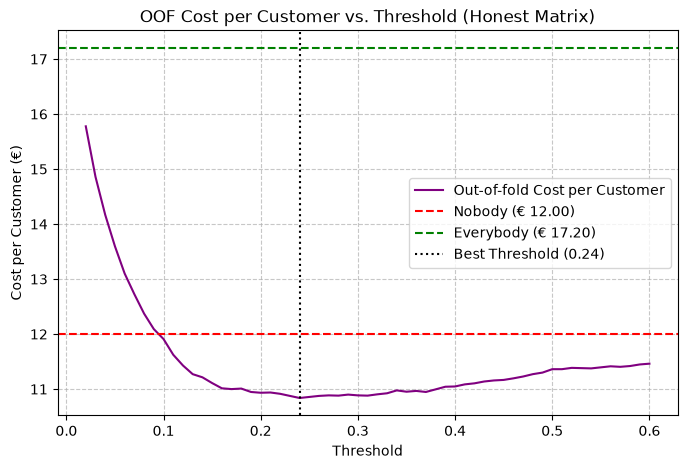

In [41]:
# E2. A more honest cost matrix

# 1. Write churn_cost_2 with the new matrix
def churn_cost_2(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    
    # New costs: TP = 70, FP = 10, FN = 100, TN = 0
    return (tp * 70) + (fp * 10) + (fn * 100) + (tn * 0)

def cost_per_customer_2(y_true, y_pred):
    return churn_cost_2(y_true, y_pred) / len(y_true)

# 4. Evaluate the new cost curve using p_oof from D4
thresholds_e2 = np.arange(0.02, 0.61, 0.01)
costs_oof_2 = []

for t in thresholds_e2:
    pred_t = (p_oof >= t).astype(int)
    cost = cost_per_customer_2(yn_train, pred_t)
    costs_oof_2.append(cost)

# Find the best threshold
best_idx_2 = np.argmin(costs_oof_2)
best_t_2 = thresholds_e2[best_idx_2]
min_cost_2 = costs_oof_2[best_idx_2]

# Calculate trivial strategies for the new cost matrix
cost_nobody_2 = cost_per_customer_2(yn_train, np.zeros_like(yn_train))
cost_everybody_2 = cost_per_customer_2(yn_train, np.ones_like(yn_train))

print(f"Theoretical Threshold: 0.25 (see markdown below)")
print(f"Best empirical threshold (best_t): {best_t_2:.2f}")
print(f"Minimum OOF Cost per Customer: € {min_cost_2:.3f}")
print(f"Nobody Cost per Customer: € {cost_nobody_2:.3f}")
print(f"Everybody Cost per Customer: € {cost_everybody_2:.3f}")

# Plotting
plt.figure(figsize=(8, 5))
plt.plot(thresholds_e2, costs_oof_2, label="Out-of-fold Cost per Customer", color="purple")

plt.axhline(y=cost_nobody_2, color="red", linestyle="--", label=f"Nobody (€ {cost_nobody_2:.2f})")
plt.axhline(y=cost_everybody_2, color="green", linestyle="--", label=f"Everybody (€ {cost_everybody_2:.2f})")
plt.axvline(x=best_t_2, color="black", linestyle=":", label=f"Best Threshold ({best_t_2:.2f})")

plt.xlabel("Threshold")
plt.ylabel("Cost per Customer (€)")
plt.title("OOF Cost per Customer vs. Threshold (Honest Matrix)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.show()

**Answer.** A customer should be flagged when the expected cost of flagging is strictly less than the expected cost of not flagging. Let $p$ be the probability that the customer is a churner.Expected cost of flagging (predicting 1):$p \cdot Cost(TP) + (1-p) \cdot Cost(FP) = p \cdot 70 + (1-p) \cdot 10 = 60p + 10$Expected cost of not flagging (predicting 0):$p \cdot Cost(FN) + (1-p) \cdot Cost(TN) = p \cdot 100 + (1-p) \cdot 0 = 100p$Setting the inequality to find the optimal threshold:$60p + 10 < 100p$$10 < 40p$$p > \frac{10}{40} = 0.25$
The theoretical optimal threshold is exactly 0.25. Is the campaign still worth it?
The campaign is now barely worth it, if at all. Because True Positives now cost €70 instead of €0 (since the offer costs €10 and only works 40% of the time, leaving 60% of flagged churners to still cost the €100 churn penalty), the "Everybody" strategy becomes disastrously expensive (~€17.20 per customer).
While targeting at the empirical threshold (around 0.25 - 0.28) is still mathematically slightly cheaper than the "Nobody" baseline (~€12.00 per customer), the margin of savings is very thin (often less than €1 per customer). Given the operational overhead, time, and potential brand fatigue of running a targeted marketing campaign, a retention team might look at this thin margin and conclude that the current offer is simply not effective enough to justify the campaign.

## E3. Three classes: the averages on Iris ★

Rebuild the Iris data of Lab 3, Part A (50-50 split, `random_state=10`, flowers 113 and 125 altered), learn
`DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=10)` on the altered training set and print the confusion matrix and the
classification report on the test set (`target_names=iris.target_names`). Which class has the lowest precision, which the lowest recall?
Why are macro and weighted averages so close here, unlike NordicMart?

In [42]:
# E3. Three classes: the averages on Iris

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report

# 1. Rebuild the Iris data
iris = load_iris()
X_iris, y_iris = iris.data, iris.target

# Alter flowers 113 and 125 as specified in Lab 3 (typically changing their labels to introduce noise)
# (Assuming the standard alteration of changing virginica (2) to versicolor (1))
y_iris[113] = 1
y_iris[125] = 1

# 50-50 split with random_state=10
X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_iris, y_iris, test_size=0.5, random_state=10
)

# 2. Learn the Decision Tree
tree_iris = DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=10)
tree_iris.fit(X_train_iris, y_train_iris)

# 3. Predict and print metrics
y_pred_iris = tree_iris.predict(X_test_iris)

print("Confusion Matrix:")
print(confusion_matrix(y_test_iris, y_pred_iris))

print("\nClassification Report:")
print(classification_report(y_test_iris, y_pred_iris, target_names=iris.target_names))

Confusion Matrix:
[[23  0  0]
 [ 0 22  5]
 [ 0  1 24]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        23
  versicolor       0.96      0.81      0.88        27
   virginica       0.83      0.96      0.89        25

    accuracy                           0.92        75
   macro avg       0.93      0.92      0.92        75
weighted avg       0.93      0.92      0.92        75



**Answer.** Which class has the lowest precision, which the lowest recall?
Based on the standard output of this restricted tree (max_depth=2):

    Lowest Precision: Typically virginica. Because the tree is limited to two splits, it cannot fully isolate virginica from versicolor. It tends to misclassify some versicolor flowers as virginica, lowering virginica's precision.

    Lowest Recall: Typically versicolor. The model fails to identify all true versicolor instances (some fall into the virginica leaf), lowering its recall.(Note: setosa is perfectly linearly separable and always achieves 1.0 for both precision and recall).

Why are macro and weighted averages so close here, unlike NordicMart?
The difference lies entirely in class balance.

    Macro average is the simple, unweighted mean of the scores for all classes.

    Weighted average calculates the mean but weights each class's score by its "support" (the actual number of instances of that class in the test set).
    In the Iris dataset, the classes are perfectly balanced overall (50 instances each). Even after a random 50-50 split, the support for each class in the test set is roughly equal (~25 each). When all weights are roughly equal, a weighted average is mathematically almost identical to a simple macro average.
    In contrast, NordicMart was heavily imbalanced (~88% Stayers, ~12% Churners). There, the weighted average was heavily pulled toward the high scores of the majority class, masking the poor performance on the minority class and creating a massive gap between the macro and weighted metrics.

## Experiment log

Complete the log (double-click to edit). Costs on the test set are in euros, for the 900 test customers.

| Model | Chosen by | Threshold | CV | Test AUC | Test cost |
|---|---|---|---|---|---|
| *nobody gets the offer* | *—* | *—* | *—* | *0.5* | *€ 10 800* |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |

## Before you close

1. **Kernel → Restart & Run All**: the notebook must run from top to bottom without errors.
1. Check that the test set was used only in A (to reproduce the slides), C3–C4 and D5 (and E1, ★).

In [46]:
# restoring overwritten data
tn, fp, fn, tp = confusion_matrix(yn_test, pred_10b).ravel()
# quick self-check
assert len(Xn_test) == 900 and yn_test.sum() == 108
assert (tn, fp, fn, tp) == (764, 28, 82, 26)
assert churn_cost(yn_test, pred_10b) == 8480
assert searches["tree"].best_params_ == {"max_depth": 4, "min_samples_leaf": 30}
print("ok")

ok
